# SpaceLLaVA: диагностика и двухкадровый smoke test

## Цель

Проверить реальную загрузку CLIP/проектора, влияние изображения на признаки и logits, а также YES/NO и форматы Q1–Q4. Это диагностика, не научный результат. Веса и benchmark-вопросы не меняются.

Старый ноутбук с результатами сохранён. Этот шаблон использует новую рабочую папку и новый RUN_ID; старые 400 ответов не перезаписываются.


## Подготовка

Включите GPU runtime. Загрузите в `MyDrive/planetary_benchmark/` два файла: `spacellava_q1_q4_v6_diagnostic.zip` и отдельный `spacellava_smoke_controls_v1.json`. Ответы контрольных примеров нужны только проверяющему коду, их нет в inference ZIP или ModelRequest. Установка окружения требует сети; веса скачиваются только при явном `DOWNLOAD_WEIGHTS=True`.


In [3]:
from pathlib import Path
import hashlib, json, os, signal, stat, subprocess, sys, uuid, zipfile, shutil
from google.colab import drive
drive.mount('/content/drive')

PERSIST = Path('/content/drive/MyDrive/planetary_benchmark')
BUNDLE_ZIP = PERSIST / 'spacellava_q1_q4_v6_diagnostic.zip'
SMOKE_CONTROLS = PERSIST / 'spacellava_smoke_controls_v1.json'
WORKSPACE = Path('/content/planetary_q1_q4_v6_diagnostics')  # Keep this path identical after reconnect for resume.
ENV_DIR = Path('/content/venv_spacellava')
PYTHON_VERSION = '3.12.15'
TORCH_INDEX = 'https://download.pytorch.org/whl/cu128'
RUN_ID = 'spacellava_q1_q4_v6_clean'
SESSION_ID = uuid.uuid4().hex  # New Colab VM/session needs a fresh smoke test.
DOWNLOAD_WEIGHTS = True  # Set True explicitly to download ~28 GB of pinned public weights/code.
WEIGHTS_SOURCE = None  # Optional existing Drive weights/ folder; copied to local WORKSPACE/weights.
RUN_BENCHMARK = False  # Set True only after the smoke test succeeds.
RESUME = False  # True only when this RUN_ID has a saved checkpoint.
CHECKPOINT_EVERY = 10  # A hard disconnect can lose at most this many uncheckpointed responses.
MAX_REQUESTS = None  # Full bundle; a smaller value is a separate fixed protocol/run_id.
PERSIST.mkdir(parents=True, exist_ok=True)
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
subprocess.run(['nvidia-smi'], check=True)
print('Bundle exists:', BUNDLE_ZIP.is_file())
print('Local free GiB:', round(shutil.disk_usage('/content').free / 1024**3, 1))
assert BUNDLE_ZIP.is_file(), 'Upload the ZIP to the configured Drive path first.'
assert SMOKE_CONTROLS.is_file(), 'Upload the separate development-control JSON to Drive first.'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Bundle exists: True
Local free GiB: 70.3


### 1. Проверить и распаковать переносимый пакет
Используй только пакет из своего проекта: в нём исполняемый код. Проверяются пути и SHA-256 всех файлов. Повторная ячейка не заменяет изменённые файлы. При новом пакете выбери новый workspace/run, не редактируй старые результаты.

In [4]:
WORKSPACE.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(BUNDLE_ZIP) as archive:
    info = archive.infolist()
    names = [item.filename for item in info]
    assert len(names) == len(set(names)), 'Duplicate archive entry'
    record = json.loads(archive.read('colab_bundle.json'))
    claimed = record.pop('bundle_sha256')
    digest = hashlib.sha256(json.dumps(record, sort_keys=True, ensure_ascii=False, allow_nan=False).encode()).hexdigest()
    assert record['schema'] == 'planetary-colab-v1' and claimed == digest, 'Metadata changed'
    assert set(names) == set(record['files_sha256']) | {'colab_bundle.json'}, 'Unexpected archive entry'
    for item in info:
        relative = Path(item.filename)
        assert not relative.is_absolute() and '..' not in relative.parts
        assert chr(92) not in item.filename and ':' not in item.filename
        assert not any(ord(c) < 32 for c in item.filename)
        assert not set(p.casefold() for p in relative.parts) & {'data_rover', '.env', '.git', 'weights', 'external'}
        assert not stat.S_ISLNK(item.external_attr >> 16) and not item.flag_bits & 1
        target = (WORKSPACE / relative).resolve()
        assert target.is_relative_to(WORKSPACE.resolve())
        data = archive.read(item)
        expected = record['files_sha256'].get(item.filename, hashlib.sha256(data).hexdigest())
        assert hashlib.sha256(data).hexdigest() == expected
        if target.exists():
            assert target.read_bytes() == data, f'Existing file differs: {relative}'
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(data)
print({key: record[key] for key in ['collection_images', 'selected_images', 'requests', 'excluded', 'counts']})
print(record['limitation'])
assert record['selected_images'] == 100 and record['requests'] == 400
assert record['protocol']['question_type'] == 'candidate_Q1_Q4_clean_unscored'
assert record['protocol']['conditions'] == ['clean']
assert record['protocol']['collection'] == 'orbital_300_v4'
print('100 images / 400 Q1-Q4 inputs verified. Answers remain local, not in this ZIP.')


{'collection_images': 300, 'selected_images': 100, 'requests': 400, 'excluded': {'publisher_train_or_ineligible': 100, 'no_admitted_question': 100}, 'counts': {'mars/segmentation/test': 33, 'mars/segmentation/val': 17, 'moon/segmentation/val': 33, 'moon/segmentation/test': 17}}
Clean RGB-only Q1-Q4 CANDIDATE inference, not accepted scoring GT. Candidate answers, masks, height arrays and targets are excluded. Complete candidates do not imply final reference admission or IBM pairing. Preserve source val/test and scene groups.
100 images / 400 Q1-Q4 inputs verified. Answers remain local, not in this ZIP.


### 2. Изолированное окружение SpaceLLaVA
Ячейка скачивает Python/dependencies, но **не модель**. Kernel Colab не меняется: все команды модели запускаются отдельным Python 3.12.15. Это исключает конфликт stock Transformers/Tokenizers в Colab и не требует Rust. CUDA wheels — кандидат; следующий шаг должен проверить драйвер/GPU.
Не ставь upstream LLaVA через `pip install -e external/LLaVA`: там устаревшие Torch pins. IBM позже получит другое окружение.

In [5]:
subprocess.run([sys.executable, '-m', 'pip', 'install', 'uv>=0.8,<1'], check=True)
if not (ENV_DIR / 'bin/python').exists():
    subprocess.run([sys.executable, '-m', 'uv', 'venv', '--python', PYTHON_VERSION, '--seed', str(ENV_DIR)], check=True)
PYTHON = str(ENV_DIR / 'bin/python')
subprocess.run([PYTHON, '-c', "import platform; assert platform.python_version() == '3.12.15'"], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'install', '--upgrade', 'pip'], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'install', 'torch==2.8.0', 'torchvision==0.23.0', '--index-url', TORCH_INDEX], check=True)
profile = WORKSPACE / 'requirements/spacellava.txt'
if RESUME:
    frozen = PERSIST / 'runs' / 'SpaceLLaVA' / RUN_ID / 'pip-freeze.txt'
    assert frozen.is_file(), 'No saved environment: use RESUME=False for a new run.'
    profile = frozen
subprocess.run([PYTHON, '-m', 'pip', 'install', '--only-binary=tokenizers', '-r', str(profile)], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'install', '--no-deps', '-e', str(WORKSPACE)], check=True)
subprocess.run([PYTHON, '-m', 'pip', 'check'], check=True)

def step(*arguments):
    command = [PYTHON, '-u', '-m', 'planetary_vlm.colab', *map(str, arguments), '--workspace', str(WORKSPACE)]
    logs = PERSIST / 'logs'
    logs.mkdir(exist_ok=True)
    import re
    assert re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_.-]{0,90}', RUN_ID)
    log_path = logs / f'{RUN_ID}_{SESSION_ID[:8]}_{arguments[0]}.log'
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace', bufsize=1)
    try:
        with log_path.open('a', encoding='utf-8') as log:
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line); log.flush()
        code = process.wait()
        if code: raise subprocess.CalledProcessError(code, command)
    except BaseException:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try: process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                process.kill(); process.wait(timeout=10)
        raise
    finally:
        process.stdout.close()

step('verify')
step('environment')

{
  "selected_images": 100,
  "requests": 400,
  "excluded": {
    "publisher_train_or_ineligible": 100,
    "no_admitted_question": 100
  },
  "counts": {
    "mars/segmentation/test": 33,
    "mars/segmentation/val": 17,
    "moon/segmentation/val": 33,
    "moon/segmentation/test": 17
  },
  "bundle_sha256": "94afe987947a8fa541be96197869c5525b645a135e003f2e697ec6a4ad7fee3a"
}
{
  "dependencies": {
    "python": "3.12.15",
    "planetary-vlm-benchmark": "0.2.0",
    "Pillow": "12.3.0",
    "numpy": "2.2.6",
    "torch": "2.8.0+cu128",
    "transformers": "4.37.2",
    "accelerate": "0.27.2",
    "bitsandbytes": "0.48.2",
    "peft": "0.9.0",
    "terratorch": null,
    "ni_lfm": null,
    "llava": null,
    "opencv-python-headless": "4.13.0.92",
    "PyYAML": "6.0.3",
    "huggingface-hub": "0.34.4",
    "tokenizers": "0.15.2",
    "safetensors": "0.8.0",
    "sentencepiece": "0.2.2",
    "timm": "0.6.13",
    "einops": "0.6.1"
  },
  "cuda": "12.8",
  "gpu": "Tesla T4",
  "gpu_memor

## Steps
### 3. Локальные веса и pinned LLaVA
Для первой загрузки включи `DOWNLOAD_WEIGHTS=True` в параметрах и повтори эту ячейку. Веса публичные; helper не скачивает train-датасеты. Требуются не менее 35 GiB свободного локального диска; реальный размер пакетов/весов может меняться.
Если веса уже есть на Drive, задай `WEIGHTS_SOURCE` на папку с `SpaceLLaVA/` и `clip-vit-large-patch14-336/`. Копирование только на локальный диск, без изменения кеша. Git repo подключается по точному commit. HF_TOKEN, если нужен, передай через Colab Secrets/environment, не записывай в notebook/логи. Исходный SSL не отключать.

In [6]:
# Reuse local pinned assets on the same VM without copying/downloading weights.
for previous in (Path('/content/planetary_q1_q4_v5'), Path('/content/planetary_colab')):
    for name in ('weights', 'external'):
        source, target = previous / name, WORKSPACE / name
        if source.is_dir() and not target.exists():
            target.symlink_to(source, target_is_directory=True)
            print('Reusing without copying:', target)


In [7]:
if WEIGHTS_SOURCE is not None:
    cache = Path(WEIGHTS_SOURCE)
    for name in ['SpaceLLaVA', 'clip-vit-large-patch14-336']:
        destination = WORKSPACE / 'weights' / name
        if not destination.exists():
            shutil.copytree(cache / name, destination)
arguments = ['assets', '--clone-runtime']  # Small pinned code clone, even when using existing weights.
if DOWNLOAD_WEIGHTS: arguments.append('--download')
step(*arguments)

Cloning into '/content/planetary_q1_q4_v6_diagnostics/external/LLaVA'...
HEAD is now at c121f04 Update README.md

Fetching 15 files: 100%|██████████| 15/15 [05:32<00:00, 22.17s/it]

Fetching 3 files: 100%|██████████| 3/3 [00:10<00:00,  3.56s/it]
{
  "assets_available": true,
  "gpu_verified": false
}


### Просмотреть контрольные снимки

Проверьте RGB и сохранённые хеши до расходования GPU-времени. Маски модели не передаются.


moon_seg_002 source split: val


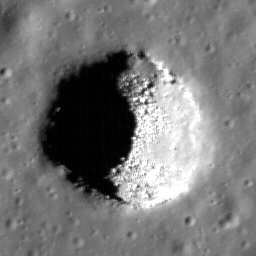

moon_seg_012 source split: val


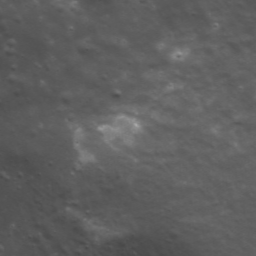

In [8]:
from IPython.display import display
from PIL import Image
controls = json.loads(SMOKE_CONTROLS.read_text())
assert controls['schema'] == 'planetary-two-image-smoke-v1'
for control in controls['controls']:
    path = WORKSPACE / 'data_orbital/colab_inputs/images' / control['sample_id'] / 'clean.png'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == control['image_sha256']
    print(control['sample_id'], 'source split:', control['source_split'])
    with Image.open(path) as image:
        display(image.convert('RGB'))


## Диагностика и smoke test

Два исходных val-снимка: `moon_seg_002` — положительный контроль; `moon_seg_012` — полный CVAT-просмотр `no_eligible_craters`. NO означает отсутствие учитываемых impact craters, а не отсутствие вообще любых неровностей. Общий reference-review остаётся pending.

Одна загрузка модели. Сначала сравниваются все тензоры CLIP/проектора с локальным merged checkpoint и проверяется отсутствие meta/NaN/Inf. Затем одинаковый короткий текст подаётся с двумя разными снимками: forward-hooks проверяют прохождение через encoder/projector, различие признаков и next-token logits. Наконец выполняются 10 запросов: Q1–Q4 и короткий Q1 на каждом снимке.

Для допуска нужны технические проверки, правильные YES/NO на четырёх Q1-контролях и допустимый формат всех десяти ответов. Q2–Q4 здесь не оцениваются на правильность. Неверные ответы сохраняются без исправления. Если проверка не прошла, полный run заблокирован. Для повторной попытки задайте свежий `SESSION_ID = uuid.uuid4().hex`; не перезапускайте полный benchmark.


In [9]:
try:
    step('smoke', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID,
         '--checkpoint-every', 1, '--smoke-controls', SMOKE_CONTROLS)
finally:
    smoke_dir = WORKSPACE / 'outputs' / 'SpaceLLaVA' / (RUN_ID + '_smoke_' + SESSION_ID[:8])
    for name in ('vision_diagnostics.json', 'smoke_assessment.json'):
        path = smoke_dir / name
        if path.is_file():
            report = json.loads(path.read_text())
            print(name, json.dumps(report, indent=2))
proof = json.loads((WORKSPACE / 'colab_smoke_passed.json').read_text())
assert proof['success'] is True and proof['session_id'] == SESSION_ID
assert proof['smoke_protocol'] == 'planetary-two-image-smoke-v1'
print('Two-image development checks passed for this session; no scientific score was computed.')


{"run_id": "spacellava_q1_q4_v6_clean_smoke_baaf415e", "backend": "spacellava", "mock": false, "component": "colab.runner", "pid": 7374, "total": 10, "event": "smoke_started", "level": "info", "timestamp": "2026-10-16T20:52:30.639518Z"}
You are using a model of type llava to instantiate a model of type llava_llama. This is not supported for all configurations of models and can yield errors.
/content/venv_spacellava/lib/python3.12/site-packages/torch/nn/modules/module.py:2441: UserWarning: for vision_model.embeddings.class_embedding: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/content/venv_spacellava/lib/python3.12/site-packages/torch/nn/modules/module.py:2441: UserWarning: for vision_model.embeddings.patch_embedding.weight: copying from a non-meta para

CalledProcessError: Command '['/content/venv_spacellava/bin/python', '-u', '-m', 'planetary_vlm.colab', 'smoke', '--persist', '/content/drive/MyDrive/planetary_benchmark', '--run-id', 'spacellava_q1_q4_v6_clean', '--session-id', 'baaf415e94674f51af959e33d33fe338', '--checkpoint-every', '1', '--smoke-controls', '/content/drive/MyDrive/planetary_benchmark/spacellava_smoke_controls_v1.json', '--workspace', '/content/planetary_q1_q4_v6_diagnostics']' returned non-zero exit status 2.

## Необязательный полный run

По умолчанию выключен. Запускайте только после успешного двухкадрового smoke в той же сессии и с тем же JSON контрольных примеров. Он выполняет неизменённые 400 benchmark-запросов; дополнительные диагностические вопросы туда не добавляются. Старый run не возобновляется новым кодом.


In [ ]:
if RUN_BENCHMARK:
    arguments = ['run', '--persist', PERSIST, '--run-id', RUN_ID, '--session-id', SESSION_ID,
                 '--checkpoint-every', CHECKPOINT_EVERY, '--smoke-controls', SMOKE_CONTROLS]
    if RESUME: arguments.append('--resume')
    if MAX_REQUESTS is not None: arguments += ['--max-requests', MAX_REQUESTS]
    step(*arguments)
else:
    print('Full benchmark disabled. First inspect the diagnostic smoke reports.')


## Сохранить диагностику

Эта ячейка работает и после неуспешного smoke: выгрузите ZIP отчётов. `vision_diagnostics.json` отвечает за технический зрительный путь, `smoke_assessment.json` — за форматы и четыре presence-контроля. Разные logits ещё не доказывают правильное понимание кратеров. При сбое загрузки отчёта forward может не быть; тогда нужен полный log.


In [10]:
smoke_name = RUN_ID + '_smoke_' + SESSION_ID[:8]
result_dir = PERSIST / 'runs' / 'SpaceLLaVA' / smoke_name
assert result_dir.is_dir(), 'Run the smoke cell first; inspect its log if no report directory was created.'
archive_path = PERSIST / (smoke_name + '_diagnostics')
exported = shutil.make_archive(str(archive_path), 'zip', root_dir=result_dir.parent, base_dir=result_dir.name)
print('Share this ZIP:', exported)
from google.colab import files
files.download(exported)


Share this ZIP: /content/drive/MyDrive/planetary_benchmark/spacellava_q1_q4_v6_clean_smoke_baaf415e_diagnostics.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Дальше

Если веса/признаки/logits не прошли проверку — исправляем загрузку или preprocessing. Если технические проверки прошли, а Q3 снова перечисляет варианты или Q1 всегда YES — исследуем prompt-following на val, сохраняя версию исходных вопросов. Не делаем вывод о качестве всей модели по двум development-снимкам и не подбираем prompts по test.

Локально проверены структура ноутбука, Python-синтаксис и CPU-фикстуры. Реальный Colab/GPU запуск этих новых проверок ещё не выполнен.
